# Catorce brazos por diez pliegues: qué puntúa cada uno y dónde se niega cada uno

**Nivel 2: El método en la práctica** · Requiere: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Tiempo de lectura: unos 35 minutos

## Objetivos

El benchmark del producto tiene catorce brazos: dos controles, la familia clásica, los estadísticos y el nivel aprendido. Cada uno responde un tiro con un número o con una negativa declarada, y una negativa es un resultado, nunca se promedia. Este cuaderno corre toda la escalera por los diez pliegues con sitio fuera y lee tanto los puntajes como las negativas.

Al terminar habrá:

- corrido los catorce brazos con un sitio fuera y reproducido el puntaje agrupado versionado de cada uno;
- listado cada negativa con su razón y la campaña de la que vino, y entendido por qué cada brazo se niega donde lo hace;
- comparado los brazos solo en los mismos tiros, que es la manera justa de ordenar brazos que responden números distintos de filas.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los catorce brazos tal como se publicaron | Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3; Sui et al. 2025, https://doi.org/10.3390/app15031254; y los artículos citados en el tema 02 | los métodos se citan, el motor los implementa | `bf.default_arms()` |
| Los puntajes agrupados y los puntajes en filas comunes versionados | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campo `protocols` |

## Método

Un brazo se niega por una de tres razones, y cada una está declarada en el motor y no escondida:

1. **No puede conocer la entrada que necesita.** La familia clásica necesita un volumen de roca y una carga, que un sitio sin diámetro de perforación publicado no puede aportar (Miami).
2. **No es un predictor de tamaño.** El discriminante de grupo asigna un grupo de rigidez de la roca; se abstiene en el tamaño para todo tiro por diseño.
3. **Su salida sale del rango físico.** Un modelo que devuelve un tamaño medio fuera del rango plausible de fragmentos, de 1 mm a un par de metros, ha salido de su dominio, y el motor rechaza el número en vez de puntuarlo. Dejar un sitio fuera y reajustar la ley de potencia publicada extrapoló una vez a 10,48 m, lo que puntuó como una varianza explicada de -11355 para ese pliegue y ahogó la cifra agrupada.

Como los brazos responden números distintos de filas, un puntaje agrupado sobre las filas propias de cada brazo compara denominadores distintos. El motor informa por eso también el puntaje de cada brazo en las filas que todos los brazos predictores de tamaño responden, las filas comunes, junto al propio y nunca como el veredicto.

### Paso 1: correr la escalera por los diez pliegues

Para cada uno de los catorce brazos la celda construye una instancia nueva por pliegue con `fit(entrenamiento)`, predice el sitio excluido y reúne las predicciones fuera de pliegue. La corrida completa toma menos de un minuto. Los brazos clásicos y los controles ignoran `fit`, como permite la clase base.

In [2]:
# Importaciones, y luego los catorce brazos con un sitio fuera
import json
import re
from collections import Counter
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
factories = bf.default_arms()
folds = list(bf.leave_one_site_out(train))
tested = [b for fold in folds for b in fold.test]
predictions = {}
for name, make in factories.items():
    out = []
    for fold in folds:
        out += make().fit(fold.train).predict(fold.test)
    predictions[name] = out
print("brazos:", len(predictions), "| tiros fuera de pliegue por brazo:", len(tested))

brazos: 14 | tiros fuera de pliegue por brazo: 97


### Paso 2: el puntaje agrupado de cada brazo, junto al versionado

La celda puntúa las filas respondidas de cada brazo y compara con el `r2_identity` agrupado versionado. También imprime el puntaje versionado en las filas comunes, los tiros que respondieron todos los brazos predictores de tamaño.

In [3]:
# r2_identity agrupado por brazo, si iguala el valor versionado, y el puntaje versionado en las filas comunes
print(f"{'brazo':<22}{'nivel':<18}{'respondió':>9}{'rechazó':>9}{'r2 identidad':>14}  {'versionado':<10}{'filas comunes':>14}")
scores = {}
for name, preds in predictions.items():
    s = bf.score(tested, preds, method=name)
    scores[name] = s
    want = loso[name]["r2_identity"]
    same = (s.r2_identity is None and want is None) or (s.r2_identity is not None and want is not None and abs(s.r2_identity - want) < 1e-9)
    common = loso[name]["common"]["score"]["r2_identity"] if "common" in loso[name] else None
    value = f"{s.r2_identity:.3f}" if s.r2_identity is not None else "-"
    common_text = f"{common:.3f}" if common is not None else "-"
    print(f"{name:<22}{loso[name]['tier']:<18}{s.n_scored:>9}{s.n_abstained:>9}{value:>14}  {str(same):<10}{common_text:>14}")

brazo                 nivel             respondió  rechazó  r2 identidad  versionado filas comunes
null                  control                  97        0        -0.216  True              -0.229
oracle                control                  97        0         1.000  True               1.000
kuznetsov             classical                91        6         0.311  True               0.318
kuznetsov-transfer    classical                91        6         0.298  True               0.293
kuznetsov-capped      classical                91        6         0.352  True               0.364
group-discriminant    statistical               0       97             -  True                   -
published-regression  statistical              97        0         0.802  True               0.766
refitted-regression   statistical              93        4        -4.075  True              -3.715
published-neural-net  learned                  97        0        -0.626  True              -0.491
svr-rbf   

### Paso 3: cada negativa, con su razón

Una negativa lleva la razón del motor como texto. La celda agrupa las negativas de cada brazo por razón (reemplazando los números dentro del texto por `#` para que razones iguales se cuenten juntas) y por la campaña de la que vinieron.

In [4]:
# Agrupar las negativas de cada brazo por razón y por campaña
for name, preds in predictions.items():
    refused = [(b, p) for b, p in zip(tested, preds) if p.abstained]
    if not refused:
        continue
    reasons = Counter(re.sub(r"[-+]?\d+\.?\d*(e[-+]?\d+)?", "#", p.abstain_reason) for _, p in refused)
    sites = Counter(b.site for b, _ in refused)
    print(f"{name} ({len(refused)} negativas) de: {dict(sites)}")
    for reason, count in reasons.items():
        print(f"    {count:>3} x {reason[:118]}")

kuznetsov (6 negativas) de: {'Miami': 6}
      6 x Miami publishes no hole diameter, so rock volume and charge mass cannot be resolved; this equation needs both
kuznetsov-transfer (6 negativas) de: {'Miami': 6}
      6 x Miami publishes no hole diameter, so rock volume and charge mass cannot be resolved; this equation needs both
kuznetsov-capped (6 negativas) de: {'Miami': 6}
      6 x Miami publishes no hole diameter, so rock volume and charge mass cannot be resolved; this equation needs both
group-discriminant (97 negativas) de: {'Akdaglar': 22, 'Dongri-Buzurg': 9, 'Enusa': 12, 'Miami': 6, 'Mrica': 11, 'Murgul': 7, 'Ozmert': 7, 'Reocin': 10, 'Reocin-UG': 6, 'Soma': 7}
     97 x this arm assigns a rock-stiffness group rather than a fragment size
refitted-regression (4 negativas) de: {'Murgul': 4}
      4 x the model returned # m, which is outside the plausible fragment range # to # m. This is the model leaving its domain, 
svr-rbf (1 negativas) de: {'Akdaglar': 1}
      1 x the model 

### Paso 4: el orden justo

La celda dibuja el puntaje agrupado de cada brazo puntuado y su puntaje en las filas comunes (los 79 tiros, de nueve campañas, que respondieron todos los brazos predictores de tamaño). Los brazos que más rechazan se puntúan en menos filas, y distintas, en la primera barra; en la segunda todos enfrentan las mismas.

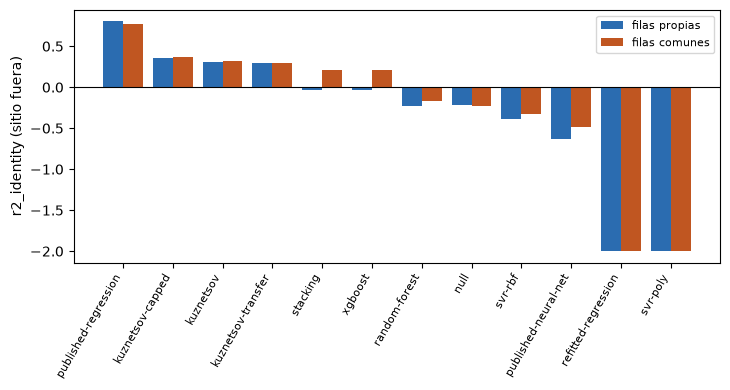

In [5]:
# Puntaje agrupado contra puntaje en filas comunes por brazo, recortado en -2 para legibilidad
ranked = [(n, scores[n].r2_identity, loso[n]["common"]["score"]["r2_identity"]) for n in scores
          if scores[n].r2_identity is not None and "common" in loso[n] and n not in ("oracle",)]
ranked.sort(key=lambda r: -r[2])
fig, ax = plt.subplots(figsize=(7.4, 4))
x = np.arange(len(ranked))
ax.bar(x - 0.2, [max(r[1], -2) for r in ranked], 0.4, color="#2b6cb0", label="filas propias")
ax.bar(x + 0.2, [max(r[2], -2) for r in ranked], 0.4, color="#c05621", label="filas comunes")
ax.set_xticks(x, [r[0] for r in ranked], rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("r2_identity (sitio fuera)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

**Los puntajes agrupados reproducen el benchmark versionado para los catorce brazos.** El oráculo puntúa un 1 perfecto, la regresión publicada un valor alto que es un ajuste en muestra (su fuente la ajustó con estos tiros), y el nulo uno claramente negativo. La ecuación clásica y sus dos variantes puntúan cerca de 0,3; gradient boosting y apilamiento quedan apenas bajo cero; el resto de los brazos aprendidos más abajo.

**Cada negativa tiene una razón y un lugar.** La familia clásica rechaza los seis tiros de Miami, cuya escala no está publicada. El discriminante de grupo rechaza los 97 porque predice un grupo. Las únicas negativas de los brazos aprendidos y reajustados son del tercer tipo: la ley de potencia reajustada rechaza cuatro tiros de Murgul, el regresor de vectores de soporte radial un tiro de Akdaglar y el polinómico once tiros de cuatro campañas, porque el modelo devolvió un tamaño fuera del rango plausible. No son fallas de cálculo; son el motor negándose a puntuar aritmética.

**Puntajes agrupados sobre filas distintas no son un orden.** El regresor de vectores de soporte polinómico se puntúa en 86 tiros y la familia clásica en 91, así que la primera barra mezcla denominadores distintos. En las filas comunes todos los brazos predictores de tamaño enfrentan los mismos 79 tiros, que dejan fuera a Miami y a todo tiro que algún brazo rechazó. Allí cambia el nivel: gradient boosting y apilamiento puntúan cerca de +0,2 en vez de cerca de -0,03, porque la campaña más fina, donde los modelos de árboles cometen algunos de sus mayores errores, ya no está en el denominador, mientras los brazos clásicos se quedan cerca de 0,3 y los aprendidos conservan casi el mismo orden. El puntaje en filas comunes se informa junto al propio del brazo y nunca decide el veredicto, porque las filas las elige la propia negativa de los brazos.

**Qué no muestra esto.** Un brazo que se niega en una fila difícil se ve mejor en las filas que responde. Por eso las negativas se cuentan en la tabla, no solo el puntaje, y el veredicto del producto no ordena los brazos por el puntaje en filas comunes.

## Resumen

- Los catorce brazos corren por los diez pliegues, y los puntajes agrupados igualan el benchmark versionado.
- Una negativa es de uno de tres tipos: una entrada que no puede conocerse, un brazo que no es predictor de tamaño, o una salida fuera del rango físico.
- Ordene los brazos en las mismas filas, e informe las negativas junto a cada puntaje.
- Siguiente: el cuaderno 03 reproduce la red neuronal publicada y muestra cuán inestable es su puntaje publicado (nivel 3).

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red y la regresión)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (bosque, boosting, apilamiento, vectores de soporte polinómico)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/